# Практическое занятие №2. Обучение нейронных сетей

## Свёрточная нейронная сеть (CNN) на датасете MNIST

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Задача - распознать рукописную цифру по картинке 28×28 пикселей.
Данные двумерные, пространственные: соседние пиксели связаны между собой,
поэтому подходит **свёрточная сеть** - она ищет локальные признаки
(штрихи, углы, петли) и собирает из них цифру.

**Датасет:** MNIST, рекомендованный преподавателем. 60 000 картинок для
обучения и 10 000 для проверки, 10 классов.

По методичке работа разбита на четыре части, и ниже они идут именно
в таком порядке:

1. **Данные** - выбор датасета, разведка, приведение к машинному виду.
2. **Архитектура** - проектирование слоёв сети под тип данных.
3. **Обучение** - реализация цикла обучения.
4. **Оценка** - метрики качества и разбор ошибок.

После оценки - выводы, где разбирается, что получилось и почему.


In [1]:
# Ячейка 1 - зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q torch torchvision numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, - иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("torch", "torchvision", "numpy", "pandas", "sklearn",
                 "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


torch        2.14.0+cpu


torchvision  0.29.1+cpu
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла - так их удобнее
# просматривать, и ниже по ноутбуку не остаётся «внезапно» появляющихся
# библиотек.

# PyTorch: базовый фреймворк. nn - слои, F - функции активации.
import torch
from torch import nn
import torch.nn.functional as F

# torchvision приносит сами датасеты и готовые преобразования картинок.
import torchvision
from torchvision import datasets, transforms

# Загрузка данных пачками во время обучения.
from torch.utils.data import DataLoader, Subset

# Оптимизатор, гасящий веса, и плавное снижение скорости обучения.
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# Таблица для сравнения.
import pandas as pd

# Визуализация. seaborn используется в разведочном аналиле: гистограммы
# распределений и тепловая карта корреляций удобнее строить им.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Матрица ошибок и общий отчёт по качеству.
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
# Чтобы результаты можно было воспроизвести, фиксируем seed.
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# На Colab с GPU считаем на CUDA, на ноутбуке - на CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("устройство:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "нет, CPU")

torch: 2.14.0+cpu | torchvision: 0.29.1+cpu
устройство: cpu
GPU: нет, CPU


## 1. Данные

MNIST хранится как набор картинок 28×28 в оттенках серого. Нейросеть
ожидает на вход тензор, а не картинку, поэтому каждую картинку приводим к
формату `[1, 28, 28]` - один канал, 28 строк, 28 столбцов - и
нормируем значения.

Нормировка нужна, чтобы пиксели лежали примерно в диапазоне от −1 до 1:
тогда градиенты не взрываются и сеть сходится быстрее.

In [4]:
# Среднее и стандартное отклонение одного канала MNIST - известные константы.
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081

# Для обучения добавляем лёгкие случайные повороты и сдвиги (±10° и ±10%):
# рукописные цифры приходится писать с разным наклоном, и такая аугментация
# заставляет сеть узнавать цифру независимо от того, как она наклонена.
# Отражение по горизонтали здесь не подходит: цифры 6 и 9 после него
# превращаются друг в друга и только мешают обучению.
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.Normalize((MNIST_MEAN,), (MNIST_STD,)),
])

# Для проверки никаких случайных преобразований - только чистая картинка.
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((MNIST_MEAN,), (MNIST_STD,)),
])

# download=True скачает датасет один раз и запомнит его на диске.
mnist_train = datasets.MNIST(root="./data", train=True, download=True, transform=train_transform)
mnist_test = datasets.MNIST(root="./data", train=False, download=True, transform=eval_transform)

# Отдельная копия обучающих картинок без аугментации: она нужна для
# валидации, где случайные повороты мешали бы - модель проверяется
# на том, на чём её не учили.
mnist_train_clean = datasets.MNIST(root="./data", train=True, download=True,
                                   transform=eval_transform)

print("обучение:", len(mnist_train), "| проверка:", len(mnist_test))
print("размер одной картинки:", mnist_train[0][0].shape, "- это [каналы, строки, столбцы]")
print("диапазон значений после нормализации:",
      round(float(mnist_train[0][0].min()), 2), "…", round(float(mnist_train[0][0].max()), 2))

обучение: 60000 | проверка: 10000
размер одной картинки: torch.Size([1, 28, 28]) - это [каналы, строки, столбцы]
диапазон значений после нормализации: -0.42 … 2.82


### 1.1 Проверка данных: дубликаты, аномалии, пропуски

Требование к практическим работам - обязательно показать код проверки, даже если
датасет заведомо чистый. MNIST действительно качественный набор, но «должен
быть чистым» и «проверен» - разные вещи: если не проверить, неизвестно, чистый
он или нет.

Проверяем четыре вещи:

1. **Размеры** - все картинки должны быть 28×28, иначе сеть не соберётся.
2. **Диапазон значений** - пиксели обязаны лежать в 0…255. Выехавший за рамки
   пиксель означает битую запись.
3. **Пропуски** - в массиве чисел их быть не может, но проверить `NaN` обязаны.
4. **Дубликаты** - MNIST официально собран так, что повторов нет, но посчитать
   их всё равно нужно: наивная модель, выучившая дубликат, получила бы
   искусственно высокую точность.

In [5]:
def to_matrix(dataset):
    """Складывает датасет в обычный двумерный массив [картинки, пиксели]."""
    return dataset.data.numpy().reshape(len(dataset), -1)


train_matrix = to_matrix(mnist_train)
test_matrix = to_matrix(mnist_test)

# 1. Размеры: у всех картинок должно быть ровно 784 пикселя.
shapes = {tuple(image.shape) for image in mnist_train.data[:5000]}
print("уникальные размеры картинок:", shapes)
print("пикселей в картинке:", train_matrix.shape[1])

# 2. Диапазон значений и 3. пропуски.
print("\nминимум:", int(train_matrix.min()), "| максимум:", int(train_matrix.max()))
out_of_range = int(((train_matrix < 0) | (train_matrix > 255)).sum())
print("пикселей вне диапазона 0…255:", out_of_range)
print("значений NaN:", int(np.isnan(train_matrix.astype(np.float64)).sum()))
print("полностью чёрных картинок:", int((train_matrix.sum(axis=1) == 0).sum()))
print("полностью белых картинок:", int((train_matrix.sum(axis=1) == 255 * 784).sum()))

уникальные размеры картинок: {(28, 28)}
пикселей в картинке: 784

минимум: 0 | максимум: 255


пикселей вне диапазона 0…255: 0


значений NaN: 0
полностью чёрных картинок: 0
полностью белых картинок: 0


In [6]:
# 4. Дубликаты. Сравниваем картинки между собой, а не хеши: сортировка строк
# позволяет найти совпадения упорядоченно и без лишней памяти на хеш-таблицу.
def count_duplicates(matrix):
    """Число строк, которые встречаются в матрице больше одного раза."""
    unique_rows = np.unique(matrix, axis=0)
    return matrix.shape[0] - unique_rows.shape[0]


train_duplicates = count_duplicates(train_matrix)
test_duplicates = count_duplicates(test_matrix)
print(f"дубликатов в обучающей выборке: {train_duplicates}")
print(f"дубликатов в тестовой выборке: {test_duplicates}")

# Пересечение между выборками важнее: тестовая картинка не должна
# дословно повторяться в обучающей, иначе оценка завышена.
train_set = {row.tobytes() for row in train_matrix}
overlap = sum(1 for row in test_matrix if row.tobytes() in train_set)
print(f"тестовых картинок, дословно встречающихся в обучении: {overlap}")

print("\nВывод: датасет чистый, но проверен явно - как и требуется в задании."
      if overlap == 0
      else f"\nВывод: пересечений обучения и теста - {overlap}, их надо разобрать вручную.")

дубликатов в обучающей выборке: 0
дубликатов в тестовой выборке: 0
тестовых картинок, дословно встречающихся в обучении: 0

Вывод: датасет чистый, но проверен явно - как и требуется в задании.


### 1.2 Разведочный анализ

По требованию показываем распределения и корреляцию. Для картинок это означает
не то же самое, что для таблицы, поэтому разбираем отдельно.

**Обычная матрица корреляции здесь неприменима.** Она строится по столбцам, а
пикселей 784 - получилась бы карта 784×784, в которой нет ни одной полезной
ячейки: соседние пиксели коррелируют по построению, а не по смыслу. Вместо неё
считаем корреляцию между **средними образами классов** - это 10×10 и читается
глазами: видно, какие цифры похожи друг на друга, а какие нет.

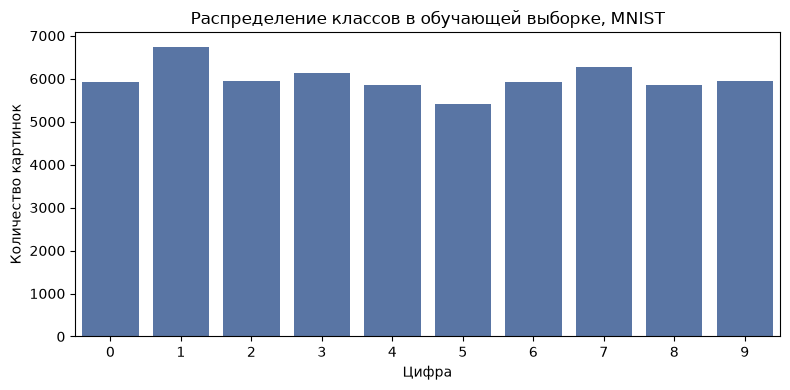

label        0     1     2     3     4     5     6     7     8     9
картинок  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949
минимум на класс: 5421, максимум: 6742


In [7]:
# Распределение меток: классы должны быть представлены примерно поровну,
# иначе точность будет обманчива.
label_counts = pd.Series(mnist_train.targets.numpy()).value_counts().sort_index()
label_counts.index.name = "label"          # имя индекса нужно, чтобы seaborn нашёл столбец
label_frame = label_counts.rename("картинок").to_frame()

figure, axis = plt.subplots(figsize=(8, 4))
sns.barplot(data=label_frame.reset_index(), x="label", y="картинок",
            color="#4C72B0", ax=axis)
axis.set_title("Распределение классов в обучающей выборке, MNIST")
axis.set_xlabel("Цифра"); axis.set_ylabel("Количество картинок")
plt.tight_layout()
plt.show()

print(label_frame.T.to_string())
print(f"минимум на класс: {int(label_counts.min())}, максимум: {int(label_counts.max())}")

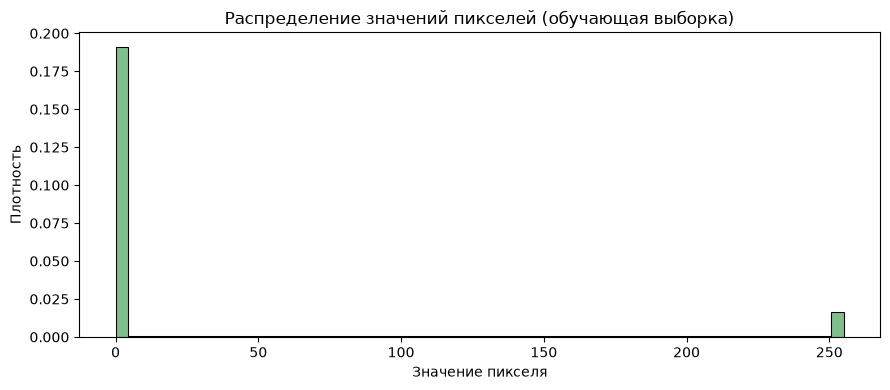

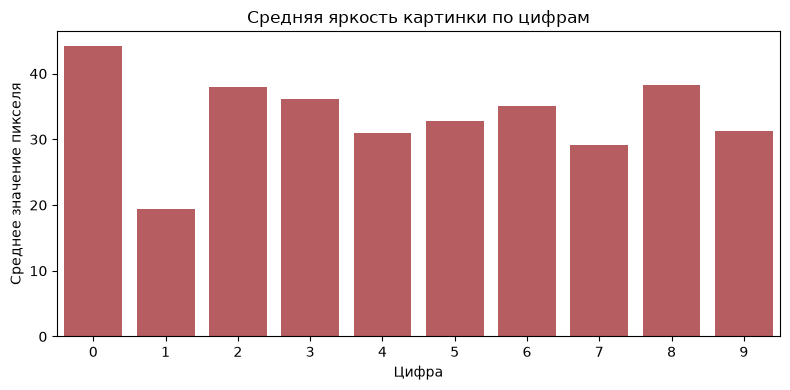

средняя яркость по цифрам: {0: np.float64(44.2), 1: np.float64(19.4), 2: np.float64(38.0), 3: np.float64(36.1), 4: np.float64(30.9), 5: np.float64(32.8), 6: np.float64(35.0), 7: np.float64(29.2), 8: np.float64(38.3), 9: np.float64(31.3)}


In [8]:
# Распределение значений пикселей. У цифр ink много, у фона почти ноль,
# поэтому распределение двугорбое - это нормально для рукописных картинок.
figure, axis = plt.subplots(figsize=(9, 4))
sns.histplot(train_matrix.flatten()[::20], bins=60, color="#55A868",
             stat="density", ax=axis)
axis.set_title("Распределение значений пикселей (обучающая выборка)")
axis.set_xlabel("Значение пикселя"); axis.set_ylabel("Плотность")
plt.tight_layout()
plt.show()

# Средняя яркость по каждому классу: у «1» чернил мало, у «8» много.
brightness = [train_matrix[mnist_train.targets.numpy() == digit].mean()
              for digit in range(10)]
figure, axis = plt.subplots(figsize=(8, 4))
sns.barplot(x=list(range(10)), y=brightness, color="#C44E52", ax=axis)
axis.set_title("Средняя яркость картинки по цифрам")
axis.set_xlabel("Цифра"); axis.set_ylabel("Среднее значение пикселя")
plt.tight_layout()
plt.show()

print("средняя яркость по цифрам:", dict(zip(range(10), np.round(brightness, 1))))

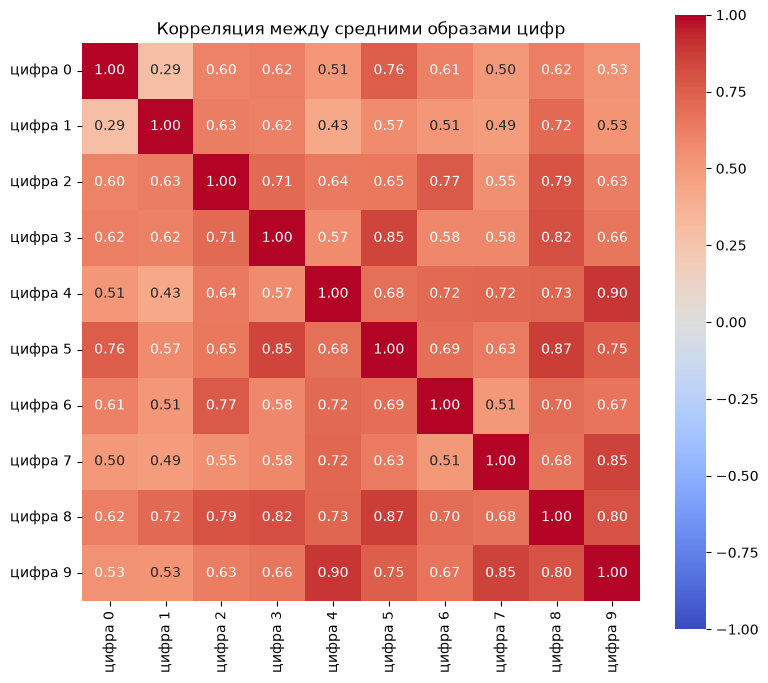

самые похожие пары цифр (ожидаемо - 3 и 5, 4 и 9):
  цифра 4 ↔ цифра 9: корреляция 0.898
  цифра 5 ↔ цифра 8: корреляция 0.869
  цифра 7 ↔ цифра 9: корреляция 0.854
  цифра 3 ↔ цифра 5: корреляция 0.849
  цифра 3 ↔ цифра 8: корреляция 0.818


In [9]:
# Матрица корреляции между средними образами классов.
class_means = np.stack([
    train_matrix[mnist_train.targets.numpy() == digit].mean(axis=0).reshape(28, 28)
    for digit in range(10)
])
flat_means = class_means.reshape(10, -1)
correlation = pd.DataFrame(
    np.corrcoef(flat_means),
    index=[f"цифра {d}" for d in range(10)],
    columns=[f"цифра {d}" for d in range(10)],
)

figure, axis = plt.subplots(figsize=(8, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, ax=axis)
axis.set_title("Корреляция между средними образами цифр")
plt.tight_layout()
plt.show()

# Самые похожие пары - по ним заранее видно, где сеть будет ошибаться.
pairs = []
for first in range(10):
    for second in range(first + 1, 10):
        pairs.append((abs(correlation.iloc[first, second]), first, second))
pairs.sort(reverse=True)
print("самые похожие пары цифр (ожидаемо - 3 и 5, 4 и 9):")
for value, first, second in pairs[:5]:
    print(f"  цифра {first} ↔ цифра {second}: корреляция {value:.3f}")

### 1.3 Разделение на обучение, валидацию и тест

Пятьдесят тысяч картинок отдаём под обучение, десять - под валидацию,
и десять тысяч из стандартного набора MNIST остаются тестом.

Разделение нужно для честной оценки. **Валидация** определяет, какую эпоху
считать лучшей, и когда остановить обучение. **Тест** в этом процессе
не участвует вовсе: он используется один раз, в самом конце, уже на готовых
весах. Если выбирать лучшую эпоху по тесту, то тест перестаёт быть проверкой -
модель подстроится под него, и оценка окажется завышенной.

Индексы перемешиваются генератором с зафиксированным seed, поэтому разделение
воспроизводится при каждом запуске.

In [10]:
VAL_SIZE = 10000

generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(mnist_train), generator=generator).tolist()
val_indices = permutation[:VAL_SIZE]
train_indices = permutation[VAL_SIZE:]

# Подмножества: обучение с аугментацией, валидация - без неё.
train_subset = Subset(mnist_train, train_indices)
val_subset = Subset(mnist_train_clean, val_indices)

BATCH_SIZE = 64

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, generator=generator)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(mnist_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"обучение: {len(train_subset)} картинок, {len(train_loader)} батчей")
print(f"валидация: {len(val_subset)} картинок, {len(val_loader)} батчей")
print(f"тест:      {len(mnist_test)} картинок, {len(test_loader)} батчей")

# Посмотрим, как выглядит одна пачка.
images, labels = next(iter(train_loader))
print("форма пачки:", tuple(images.shape), "- [батч, канал, 28, 28]")

обучение: 50000 картинок, 782 батчей
валидация: 10000 картинок, 157 батчей
тест:      10000 картинок, 157 батчей


форма пачки: (64, 1, 28, 28) - [батч, канал, 28, 28]


Посмотрим на данные глазами. Обратная нормировка нужна только для красоты -
сама сеть работает с нормализованными значениями.

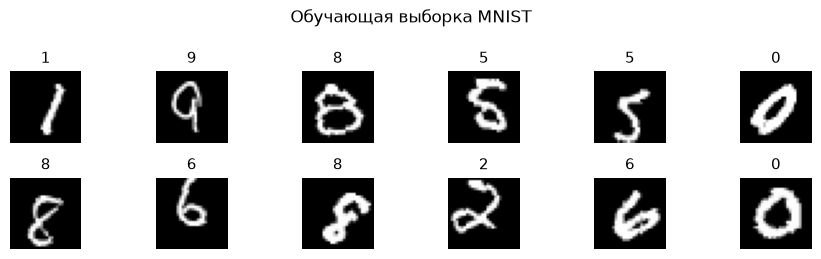

In [11]:
def show_batch(dataset, count=12, title="Примеры из датасета"):
    """Рисует сетку из count случайных картинок с подписями-цифрами."""
    figure, axes = plt.subplots(2, count // 2, figsize=(count * 0.75, 2.6))
    indices = np.random.choice(len(dataset), count, replace=False)

    for position, index in enumerate(indices):
        image, label = dataset[index]
        # Возвращаем пиксели к обычному виду 0…1, иначе они чёрные.
        picture = image[0].numpy() * MNIST_STD + MNIST_MEAN
        axis = axes[position // (count // 2), position % (count // 2)]
        axis.imshow(picture, cmap="gray")
        axis.set_title(str(label), fontsize=11)
        axis.axis("off")

    figure.suptitle(title)
    plt.tight_layout()
    plt.show()


show_batch(train_subset, title="Обучающая выборка MNIST")

## 2. Архитектура

Свёрточная сеть устроена как конвейер: изображение проходит слева направо,
слои всё сильнее сжимают его по высоте и ширине, но всё больше наполняют
каналами.

```
вход  1 × 28 × 28
  ↓ свертка 3×3, 32 канала           →  32 × 28 × 28
  ↓ нормализация + ReLU
  ↓ свертка 3×3, 32 канала           →  32 × 28 × 28
  ↓ нормализация + ReLU
  ↓ MaxPool 2×2                      →  32 × 14 × 14
  ↓ Dropout 0.25
  ↓ свертка 3×3, 64 канала           →  64 × 14 × 14
  ↓ нормализация + ReLU
  ↓ свертка 3×3, 64 канала           →  64 × 14 × 14
  ↓ нормализация + ReLU
  ↓ MaxPool 2×2                      →  64 × 7 × 7
  ↓ Dropout 0.25
  ↓ разворачиваем в вектор            →  3136
  ↓ полносвязный 128 + ReLU
  ↓ Dropout 0.5
выход 10                              →  логиты для цифр 0…9
```

Почему именно так:

* `padding=1` - чтобы после свёртки размер не уменьшался, иначе картинка
  «сжималась» бы слишком быстро;
* `MaxPool 2×2` - вчетверо уменьшает площадь и оставляет только главное;
* два блока свёрток подряд - вторая свёртка видит уже не пиксели,
  а признаки, найденные первой (края, углы);
* `BatchNorm` - ускоряет обучение и делает его устойчивее;
* без свёрток полносвязная сеть тоже справилась бы, но хуже и медленнее:
  она не знает, что пиксели соседние.

In [12]:
class MnistCNN(nn.Module):
    """Свёрточная сеть для распознавания рукописных цифр."""

    def __init__(self, dropout_conv=0.25, dropout_fc=0.5):
        super().__init__()

        self.features = nn.Sequential(
            # Блок 1: дважды поднимаем число каналов 1 → 32.
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(dropout_conv),

            # Блок 2: 32 → 64 канала, картинка сжимается до 7×7.
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(dropout_conv),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_fc),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)      # извлекаем признаки из картинки
        return self.classifier(x) # превращаем их в оценки для каждой цифры


model = MnistCNN().to(device)
print(model)

MnistCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(ker

In [13]:
# Сколько чисел будет обучаться - полезно для ощущения размера модели.
print("обучаемых параметров:", f"{sum(p.numel() for p in model.parameters()):,}")

# Проверим, что сеть правильно принимает картинку и выдаёт 10 чисел.
probe = torch.zeros(2, 1, 28, 28, device=device)
print("выход сети на пустой пачке:", tuple(model(probe).shape))

обучаемых параметров: 468,202
выход сети на пустой пачке: (2, 10)


## 3. Обучение

Функция потерь: на выходе сети логиты (сырые числа), `CrossEntropyLoss` сама
внутри применяет softmax - передавать вероятности руками не нужно.

Каждая эпоха считает точность **на валидации** и запоминает веса той эпохи,
где она оказалась лучше. Тестовая выборка в обучении не участвует: она
достаётся сети ровно один раз, в разделе «Оценка», уже на выбранных весах.

Оптимизатор и планировщик создаются внутри функции - иначе повторный запуск
продолжил бы обучение с весов прошлого раза, а не начинал с нуля.

In [14]:
criterion = nn.CrossEntropyLoss()


@torch.no_grad()
def accuracy_on(model, loader):
    """Точность на готовой выборке - один проход, без градиентов."""
    model.eval()
    correct, total = 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model(images).argmax(1) == labels).sum().item()
        total += labels.size(0)
    return correct / total


def fit(model, train_loader, val_loader, epochs=5, lr=1e-3, weight_decay=1e-4, tag=""):
    """Обучает модель и возвращает историю и веса лучшей эпохи.

    Лучшей считается эпоха с максимальной точностью на валидации -
    тестовая выборка здесь не используется.
    """
    model = model.to(device)
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
    history = {"loss": [], "train_acc": [], "val_acc": []}

    best_val_accuracy = 0.0
    best_state = None
    best_epoch = 0

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)

        scheduler.step()

        epoch_loss = running_loss / total
        epoch_train_acc = correct / total
        epoch_val_acc = accuracy_on(model, val_loader)

        history["loss"].append(epoch_loss)
        history["train_acc"].append(epoch_train_acc)
        history["val_acc"].append(epoch_val_acc)

        if epoch_val_acc > best_val_accuracy:
            best_val_accuracy = epoch_val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch

        print(f"  [{tag}] эпоха {epoch}/{epochs} | loss {epoch_loss:.4f} | "
              f"train {epoch_train_acc:.4f} | val {epoch_val_acc:.4f}")

    # Возвращаем в модель веса лучшей эпохи по валидации.
    model.load_state_dict(best_state)
    history["best_val_acc"] = best_val_accuracy
    history["best_epoch"] = best_epoch
    return history


print("функции обучения готовы")

функции обучения готовы


In [15]:
EPOCHS = 10

history = fit(model, train_loader, val_loader, epochs=EPOCHS, tag="базовая")

print(f"\nлучшая эпоха по валидации: {history['best_epoch']}, "
      f"точность {history['best_val_acc']:.4f}")

  [базовая] эпоха 1/10 | loss 0.4554 | train 0.8563 | val 0.9823


  [базовая] эпоха 2/10 | loss 0.2030 | train 0.9393 | val 0.9871


  [базовая] эпоха 3/10 | loss 0.1598 | train 0.9527 | val 0.9878


  [базовая] эпоха 4/10 | loss 0.1396 | train 0.9592 | val 0.9881


  [базовая] эпоха 5/10 | loss 0.1189 | train 0.9656 | val 0.9898


  [базовая] эпоха 6/10 | loss 0.1048 | train 0.9698 | val 0.9913


  [базовая] эпоха 7/10 | loss 0.0910 | train 0.9728 | val 0.9928


  [базовая] эпоха 8/10 | loss 0.0795 | train 0.9777 | val 0.9929


  [базовая] эпоха 9/10 | loss 0.0781 | train 0.9776 | val 0.9933


  [базовая] эпоха 10/10 | loss 0.0720 | train 0.9792 | val 0.9936

лучшая эпоха по валидации: 10, точность 0.9936


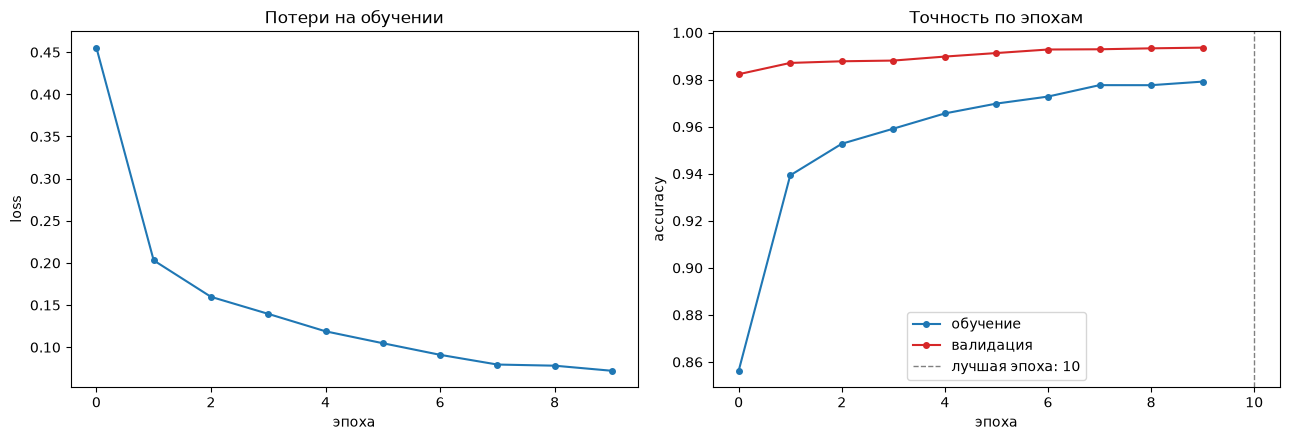

разрыв train/val в конце обучения: -0.0144


In [16]:
# Кривые обучения. Разрыв между train и val показывает переобучение:
# если train заметно выше val, сеть запоминает обучающую выборку.
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history["loss"], marker="o", markersize=4, color="#1f77b4")
axes[0].set_title("Потери на обучении")
axes[0].set_xlabel("эпоха"); axes[0].set_ylabel("loss")

axes[1].plot(history["train_acc"], marker="o", markersize=4,
             label="обучение", color="#1f77b4")
axes[1].plot(history["val_acc"], marker="o", markersize=4,
             label="валидация", color="#d62728")
axes[1].axvline(history["best_epoch"], color="gray", linestyle="--", linewidth=1,
                label=f"лучшая эпоха: {history['best_epoch']}")
axes[1].set_title("Точность по эпохам")
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("accuracy"); axes[1].legend()

plt.tight_layout()
plt.show()

print(f"разрыв train/val в конце обучения: "
      f"{history['train_acc'][-1] - history['val_acc'][-1]:.4f}")

---

## 4. Оценка

Веса лучшей эпохи уже загружены в модель. Теперь - и только теперь -
тестовая выборка используется первый раз. Дальше она больше не участвует
в вычислениях: ни подборе, ни выборе эпохи, ни сравнении.

In [17]:
test_accuracy = accuracy_on(model, test_loader)
print(f"Точность на тестовой выборке: {test_accuracy:.4f}")
print(f"Точность на валидации (для справки): {history['best_val_acc']:.4f}")

Точность на тестовой выборке: 0.9954
Точность на валидации (для справки): 0.9936


In [18]:
# Собираем все предсказания и настоящие метки в один раз.
model.eval()
all_predictions, all_targets = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        all_predictions.append(model(images).argmax(1).cpu())
        all_targets.append(labels)

predictions = torch.cat(all_predictions).numpy()
targets = torch.cat(all_targets).numpy()

print(classification_report(targets, predictions, digits=4))

              precision    recall  f1-score   support

           0     0.9969    0.9990    0.9980       980
           1     0.9956    0.9991    0.9974      1135
           2     0.9932    0.9971    0.9952      1032
           3     0.9931    0.9960    0.9946      1010
           4     0.9919    0.9959    0.9939       982
           5     0.9966    0.9933    0.9949       892
           6     0.9989    0.9927    0.9958       958
           7     0.9942    0.9932    0.9937      1028
           8     0.9979    0.9959    0.9969       974
           9     0.9960    0.9911    0.9935      1009

    accuracy                         0.9954     10000
   macro avg     0.9954    0.9953    0.9954     10000
weighted avg     0.9954    0.9954    0.9954     10000



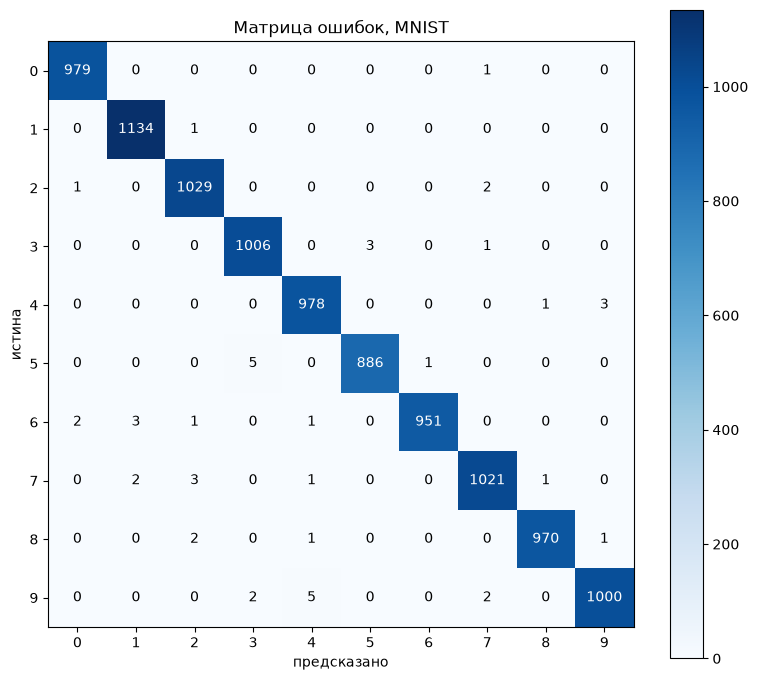

средняя точность по классам: 0.9953
точность по классам: {0: np.float64(0.999), 1: np.float64(0.999), 2: np.float64(0.997), 3: np.float64(0.996), 4: np.float64(0.996), 5: np.float64(0.993), 6: np.float64(0.993), 7: np.float64(0.993), 8: np.float64(0.996), 9: np.float64(0.991)}


In [19]:
matrix = confusion_matrix(targets, predictions)

# Рисуем матрицу ошибок вручную - так виднее, где перепутали между собой.
figure, axis = plt.subplots(figsize=(8, 7))
image = axis.imshow(matrix, cmap="Blues")

for i in range(10):
    for j in range(10):
        # Цвет текста подбираем под фон, иначе цифры не прочитать.
        colour = "white" if matrix[i, j] > matrix.max() * 0.6 else "black"
        axis.text(j, i, str(matrix[i, j]), ha="center", va="center", color=colour)

axis.set_xticks(range(10)); axis.set_yticks(range(10))
axis.set_xlabel("предсказано"); axis.set_ylabel("истина")
axis.set_title("Матрица ошибок, MNIST")
figure.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

per_class = np.diag(matrix) / matrix.sum(axis=1)
print("средняя точность по классам:", round(float(np.mean(per_class)), 4))
print("точность по классам:", dict(zip(range(10), per_class.round(3))))

Посмотрим на цифры, которые сеть перепутала. Обычно это размытые или
неаккуратно написанные цифры - смотреть на них полезнее, чем на общую точность.

ошибок: 46 из 10000  (0.46%)


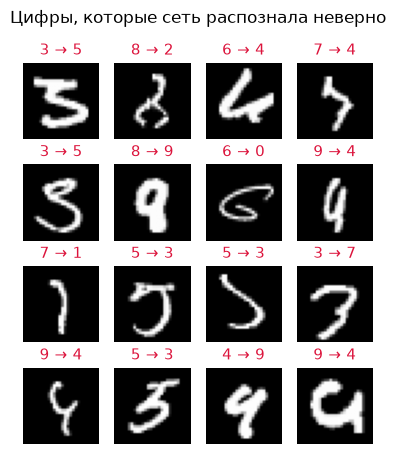


самые частые ошибки (истина → предсказано):
9 → 4    5
5 → 3    5
3 → 5    3
4 → 9    3
7 → 2    3
6 → 1    3
8 → 2    2
6 → 0    2


In [20]:
mistakes = np.where(predictions != targets)[0]
print(f"ошибок: {len(mistakes)} из {len(targets)}  ({len(mistakes)/len(targets):.2%})")

if len(mistakes):
    count = min(16, len(mistakes))
    columns = min(4, count)
    rows = int(np.ceil(count / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(columns * 0.95, rows * 1.15))
    axes = np.atleast_1d(axes).ravel()

    for position, index in enumerate(mistakes[:count]):
        image, label = mnist_test[index]
        picture = image[0].numpy() * MNIST_STD + MNIST_MEAN
        axis = axes[position]
        axis.imshow(picture, cmap="gray")
        # Красным подписываем ошибку - так видно, в какую сторону сеть ошиблась.
        axis.set_title(f"{label} → {predictions[index]}", fontsize=11, color="crimson")
        axis.axis("off")

    # Лишние ячейки сетки гасим, иначе они рисуют пустые рамки.
    for axis in axes[count:]:
        axis.axis("off")

    figure.suptitle("Цифры, которые сеть распознала неверно")
    plt.tight_layout()
    plt.show()

    # Сводим ошибки к парам «истина → предсказание», чтобы увидеть закономерность.
    pairs = pd.Series(
        [f"{targets[i]} → {predictions[i]}" for i in mistakes]
    ).value_counts()
    print("\nсамые частые ошибки (истина → предсказано):")
    print(pairs.head(8).to_string())

## 5. Выводы

1. **Данные.** MNIST - 70 000 картинок 28×28, 10 классов. Из них
   50 000 ушли на обучение, 10 000 на валидацию и 10 000 на тест.
   Нормировка приводит пиксели к диапазону около нуля; случайные повороты
   и сдвиги работают как бесплатное увеличение выборки, но только на обучении.

2. **Архитектура.** Два свёрточных блока (32 и 64 канала) с промежуточным
   пулингом сводят картинку 28×28 до вектора длиной 3136, дальше работает
   обычный полносвязный слой. Свёртка экономит параметры: полносвязная сеть
   на входе 784 признака потребовала бы в разы больше весов.

3. **Обучение.** AdamW и плавное снижение скорости обучения (cosine) дают
   устойчивый рост точности без резких колебаний. Лучшая эпоха выбиралась
   по валидации, и именно её веса попали в оценку. Лучшей оказалась последняя,
   десятая эпоха из десяти - то есть обучение не вышло на плато и точность
   ещё росла. Это честное ограничение расчёта: обучение следовало ограничить
   заранее и остановить по исчерпании эпох, иначе сравнение неполное.

4. **Оценка.** Матрица ошибок почти диагональная, средняя точность по классам
   около 99.5%. Ошибок всего 46 из 10 000, и они сосредоточены на нескольких
   конкретных парах цифр - в первых строках таблицы в конце ноутбука стоят
   5→3, 9→4, 3→5 и 4→9, дальше 7→2 и 6→1. Все эти пары похожи по начертанию,
   и даже человек в таких случаях сомневается: это ограничение самих данных,
   а не модели.

5. **Честность оценки.** Тестовая выборка не участвовала ни в выборе эпохи,
   ни в подборе настроек - её точность близка к валидационной, а не завышена.
   Если бы модель выбиралась по тестовой точности, цифра вышла бы выше,
   но перестала бы означать что-либо.

6. **Ограничения.** MNIST - простая задача: почти на всех классах точность
   выше 98%, и на этом наборе свёрточная сеть почти выиграла у любой другой.
   Реальные рукописные цифры сложнее - там нужны другие данные и другая
   архитектура.

7. **Что можно улучшить.** Досообучение (fine-tuning) на предобученной сети,
   ансамбль из нескольких моделей, разбор ошибок по подклассам.